# TrustLedger — model training

Credit scoring for people without a credit history. Team Minus One, International AI Builders Congress 2026.

Datasets go in `datasets/`. Figures are written to `training_files/`, trained models to `models/`.

In [1]:
import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, balanced_accuracy_score
from sklearn.calibration import calibration_curve

SEED = 42
rng = np.random.default_rng(SEED)

DATA, FIGS, MODELS = "datasets", "training_files", "models"
os.makedirs(FIGS, exist_ok=True)
os.makedirs(MODELS, exist_ok=True)

HC_FILE = f"{DATA}/home-credit-default-risk/application_train.csv"
LC_FILE = f"{DATA}/accepted_2007_to_2018Q4.csv"
FINDEX_FILE = f"{DATA}/Findex_Microdata_2025_updateBangladesh.csv"

metrics = {}

def save(name):
    plt.savefig(f"{FIGS}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

for f in [HC_FILE, LC_FILE, FINDEX_FILE]:
    print(("found   " if os.path.exists(f) else "missing ") + f)

found   datasets/home-credit-default-risk/application_train.csv
found   datasets/accepted_2007_to_2018Q4.csv
found   datasets/Findex_Microdata_2025_updateBangladesh.csv


In [2]:
sig = lambda z: 1 / (1 + np.exp(-z))

def fit_xgb(Xtr, ytr, Xva, yva, depth=5):
    m = xgb.XGBClassifier(n_estimators=1500, max_depth=depth, learning_rate=0.03, subsample=0.85,
                          colsample_bytree=0.8, min_child_weight=10, eval_metric="auc",
                          early_stopping_rounds=75, tree_method="hist", enable_categorical=True,
                          random_state=SEED)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m

def scores(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return {"auc": round(roc_auc_score(y, p), 4), "ks": round(float(np.max(tpr - fpr)), 4),
            "brier": round(brier_score_loss(y, p), 4)}

def plot_roc_calibration(y, p, title, name):
    fpr, tpr, _ = roc_curve(y, p)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(fpr, tpr, label=f"AUC {roc_auc_score(y, p):.3f}")
    ax[0].plot([0, 1], [0, 1], "--", c="grey")
    ax[0].set(title=f"{title} — ROC", xlabel="false positive rate", ylabel="true positive rate")
    ax[0].legend()
    frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax[1].plot(mean_p, frac, "o-")
    ax[1].plot([0, 1], [0, 1], "--", c="grey")
    ax[1].set(title=f"{title} — calibration", xlabel="predicted P(repay)", ylabel="observed repay rate")
    plt.tight_layout()
    save(name)

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def group_table(y, approved, groups):
    d = pd.DataFrame({"y": np.asarray(y), "a": np.asarray(approved), "g": np.asarray(groups)})
    t = pd.DataFrame({"approval_rate": d.groupby("g").a.mean(),
                      "tpr": d[d.y == 1].groupby("g").a.mean(),
                      "fpr": d[d.y == 0].groupby("g").a.mean()})
    spread = lambda s: float(s.max() - s.min())
    return t, spread(t.approval_rate), spread(t.tpr), max(spread(t.tpr), spread(t.fpr))

def to_score(p):
    # 600 points at 4:1 odds, +50 per doubling, clipped to 300-900
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.clip(600 + 50 / np.log(2) * np.log(p / (1 - p) / 4), 300, 900).round().astype(int)

## 1. Findex 2025 — Bangladesh context

Account ownership in the survey, weighted. This is the gap TrustLedger is aimed at.

all adults               0.433
women                    0.333
men                      0.535
borrowed (any source)    0.703
dtype: float64


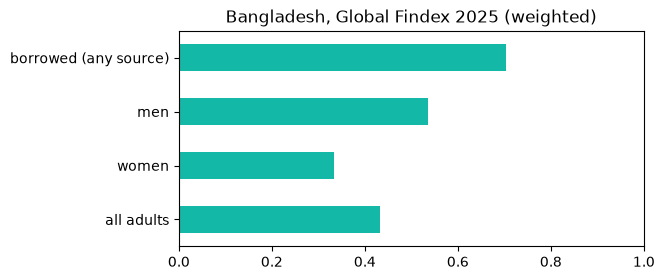

In [3]:
if os.path.exists(FINDEX_FILE):
    fx = pd.read_csv(FINDEX_FILE, low_memory=False)
    fx.columns = fx.columns.str.lower()
    w = fx["wgt"] if "wgt" in fx else pd.Series(1.0, index=fx.index)
    wmean = lambda col, mask=slice(None): float(np.average(fx.loc[mask, col], weights=w[mask]))

    if "account" in fx:
        fx["account"] = (fx["account"] == 1).astype(int)
        rows = {"all adults": wmean("account")}
        if "female" in fx:  # findex coding: 1 = female, 2 = male
            rows["women"] = wmean("account", fx.female == 1)
            rows["men"] = wmean("account", fx.female == 2)
        if "borrowed" in fx:
            fx["borrowed"] = (fx["borrowed"] == 1).astype(int)
            rows["borrowed (any source)"] = wmean("borrowed")
        findex = pd.Series(rows).round(3)
        print(findex)
        metrics["findex_bd"] = findex.to_dict()

        findex.plot.barh(figsize=(6, 2.8), color="#14B8A6")
        plt.title("Bangladesh, Global Findex 2025 (weighted)")
        plt.xlim(0, 1)
        save("findex_bangladesh")
    else:
        print("no 'account' column found; columns:", list(fx.columns)[:30])

## 2. Home Credit — real thin-file borrowers

`EXT_SOURCE_1/2/3` are external bureau scores. Many applicants don't have them. Three models are compared:
bureau scores only, alternative data only (no bureau scores), and both. The alternative-data model is the one that matters for TrustLedger.
Gender is only used for the fairness check, never as a model input.

In [4]:
RUN_HC = os.path.exists(HC_FILE)
if RUN_HC:
    hc = pd.read_csv(HC_FILE)
    hc = hc[hc.CODE_GENDER.isin(["F", "M"])].copy()
    hc["repaid"] = 1 - hc.TARGET
    hc["DAYS_EMPLOYED"] = hc.DAYS_EMPLOYED.replace(365243, np.nan)

    hc["credit_income"] = hc.AMT_CREDIT / hc.AMT_INCOME_TOTAL
    hc["annuity_income"] = hc.AMT_ANNUITY / hc.AMT_INCOME_TOTAL
    hc["term_months"] = hc.AMT_CREDIT / hc.AMT_ANNUITY
    hc["goods_credit"] = hc.AMT_GOODS_PRICE / hc.AMT_CREDIT
    hc["income_per_person"] = hc.AMT_INCOME_TOTAL / hc.CNT_FAM_MEMBERS
    hc["years_employed"] = -hc.DAYS_EMPLOYED / 365
    hc["years_same_phone"] = -hc.DAYS_LAST_PHONE_CHANGE / 365
    hc["years_id"] = -hc.DAYS_ID_PUBLISH / 365
    hc["years_registered"] = -hc.DAYS_REGISTRATION / 365
    hc["contact_channels"] = hc[["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL"]].sum(axis=1)
    hc["social_default_rate"] = hc.DEF_30_CNT_SOCIAL_CIRCLE / hc.OBS_30_CNT_SOCIAL_CIRCLE.replace(0, np.nan)
    hc["docs_provided"] = hc.filter(like="FLAG_DOCUMENT_").sum(axis=1)
    hc["own_car"] = (hc.FLAG_OWN_CAR == "Y").astype(int)
    hc["own_realty"] = (hc.FLAG_OWN_REALTY == "Y").astype(int)
    hc["no_bureau"] = hc.EXT_SOURCE_1.isna() & hc.EXT_SOURCE_3.isna()
    hc["group"] = hc.CODE_GENDER + "_R" + hc.REGION_RATING_CLIENT_W_CITY.astype(str)

    cats = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE",
            "NAME_CONTRACT_TYPE", "NAME_FAMILY_STATUS", "ORGANIZATION_TYPE"]
    for c in cats:
        hc[c] = hc[c].astype("category")

    alt = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "credit_income",
           "annuity_income", "term_months", "goods_credit", "income_per_person", "years_employed",
           "years_same_phone", "years_id", "years_registered", "contact_channels", "social_default_rate",
           "docs_provided", "own_car", "own_realty", "CNT_CHILDREN", "CNT_FAM_MEMBERS",
           "REGION_POPULATION_RELATIVE", "OBS_30_CNT_SOCIAL_CIRCLE", "DEF_30_CNT_SOCIAL_CIRCLE",
           "REG_CITY_NOT_WORK_CITY", "LIVE_CITY_NOT_WORK_CITY"] + cats
    bureau = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

    hc_tr, rest = train_test_split(hc, test_size=0.4, stratify=hc.repaid, random_state=SEED)
    hc_va, hc_te = train_test_split(rest, test_size=0.5, stratify=rest.repaid, random_state=SEED)
    print(f"{len(hc):,} applicants, repay rate {hc.repaid.mean():.3f}, no bureau score {hc.no_bureau.mean():.1%}")

307,507 applicants, repay rate 0.919, no bureau score 11.9%


                  auc_all  auc_no_bureau
bureau only        0.7254         0.6669
alternative data   0.7031         0.6932
both               0.7601         0.7203


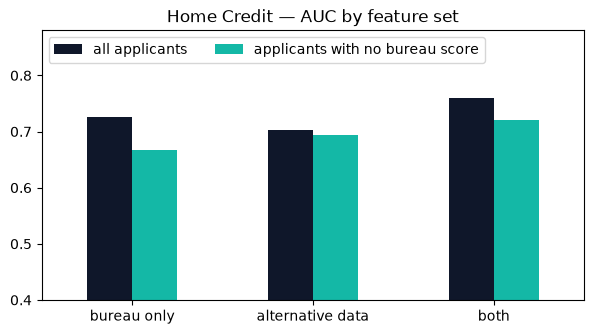

In [5]:
if RUN_HC:
    comparison, hc_models = {}, {}
    thin = hc_te.no_bureau.values
    for name, feats in {"bureau only": bureau, "alternative data": alt, "both": alt + bureau}.items():
        m = fit_xgb(hc_tr[feats], hc_tr.repaid, hc_va[feats], hc_va.repaid)
        p = m.predict_proba(hc_te[feats])[:, 1]
        comparison[name] = {"auc_all": roc_auc_score(hc_te.repaid, p),
                            "auc_no_bureau": roc_auc_score(hc_te.repaid[thin], p[thin])}
        hc_models[name] = (m, feats, p)
    comparison = pd.DataFrame(comparison).T.round(4)
    print(comparison)

    comparison.plot.bar(rot=0, figsize=(7, 3.5), color=["#0F172A", "#14B8A6"])
    plt.ylim(0.4, comparison.values.max() + 0.12)
    plt.title("Home Credit — AUC by feature set")
    plt.legend(["all applicants", "applicants with no bureau score"], loc="upper left", ncol=2)
    save("homecredit_feature_sets")

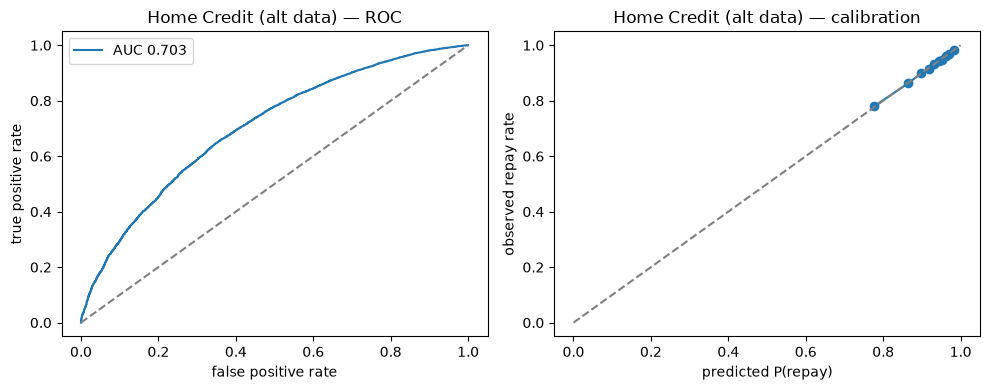

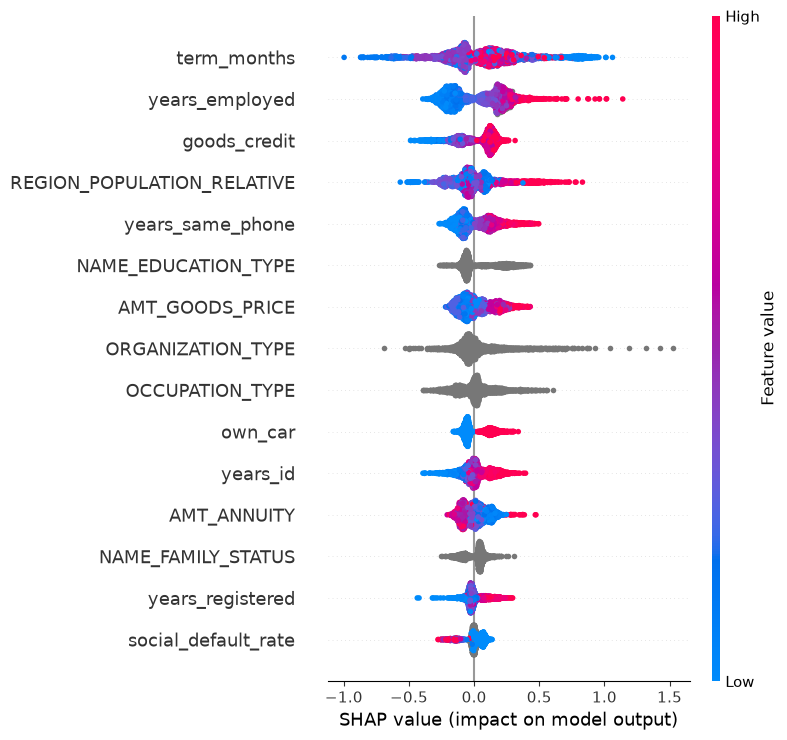

            before                       after              
     approval_rate    tpr    fpr approval_rate    tpr    fpr
g                                                           
F_R1         0.836  0.846  0.625         0.612  0.625  0.335
F_R2         0.640  0.659  0.380         0.604  0.623  0.350
F_R3         0.535  0.559  0.295         0.609  0.635  0.360
M_R1         0.750  0.766  0.494         0.621  0.640  0.318
M_R2         0.503  0.529  0.266         0.599  0.624  0.368
M_R3         0.407  0.444  0.186         0.596  0.638  0.345
TPR gap 0.402 -> 0.018


In [6]:
if RUN_HC:
    hc_model, hc_feats, p_hc = hc_models["alternative data"]
    plot_roc_calibration(hc_te.repaid, p_hc, "Home Credit (alt data)", "homecredit_roc_calibration")

    sample = hc_te[hc_feats].sample(min(3000, len(hc_te)), random_state=SEED)
    shap.summary_plot(shap.TreeExplainer(hc_model).shap_values(sample), sample, max_display=15, show=False)
    save("homecredit_shap")

    # fairness: real default rates differ between groups, so equal opportunity (same TPR) is the target
    p_va_hc = hc_model.predict_proba(hc_va[hc_feats])[:, 1]
    thr = youden(hc_va.repaid, p_va_hc)
    target_tpr = ((p_va_hc >= thr) & (hc_va.repaid == 1)).sum() / (hc_va.repaid == 1).sum()
    hc_thr = {g: float(np.quantile(p_va_hc[(hc_va.group == g) & (hc_va.repaid == 1)], 1 - target_tpr))
              for g in hc_va.group.unique()}

    before = (p_hc >= thr).astype(int)
    after = np.array([int(p >= hc_thr[g]) for p, g in zip(p_hc, hc_te.group)])
    tb, _, tpr_gap_b, _ = group_table(hc_te.repaid, before, hc_te.group)
    ta, _, tpr_gap_a, _ = group_table(hc_te.repaid, after, hc_te.group)
    print(pd.concat({"before": tb, "after": ta}, axis=1).round(3))
    print(f"TPR gap {tpr_gap_b:.3f} -> {tpr_gap_a:.3f}")

    metrics["home_credit"] = {**scores(hc_te.repaid, p_hc),
                              "comparison": comparison.to_dict(orient="index"),
                              "tpr_gap_before": round(tpr_gap_b, 3), "tpr_gap_after": round(tpr_gap_a, 3)}
    hc_model.save_model(f"{MODELS}/homecredit_alt_xgb.json")
    json.dump({"features": hc_feats, "threshold": thr, "group_thresholds": hc_thr},
              open(f"{MODELS}/homecredit_meta.json", "w"), indent=2)

## 3. LendingClub — benchmark

Resolved loans only (fully paid / charged off). No gender field, so this is a performance check only.
`LC_ROWS` limits how much of the 1.6 GB file is read; set it to `None` for everything.

{'loans': 422373, 'auc': 0.7366, 'ks': 0.3474, 'brier': 0.1425}


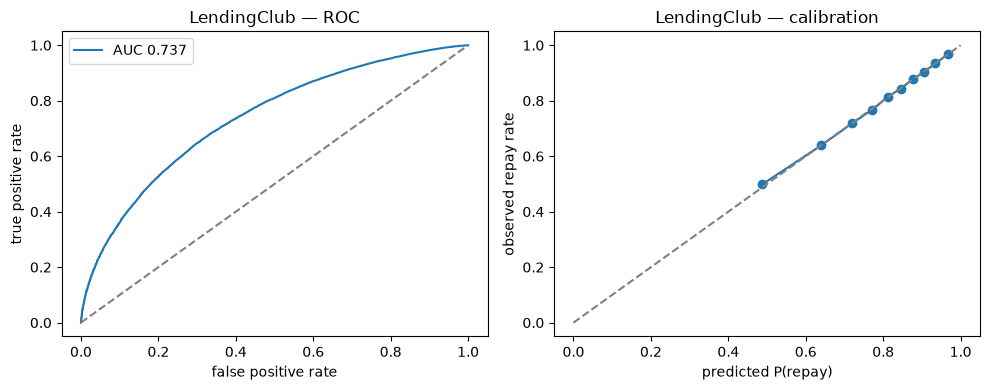

In [7]:
LC_ROWS = 600_000
RUN_LC = os.path.exists(LC_FILE)
if RUN_LC:
    keep = ["loan_status", "loan_amnt", "term", "int_rate", "installment", "annual_inc", "dti", "emp_length",
            "home_ownership", "verification_status", "purpose", "revol_util", "revol_bal", "inq_last_6mths",
            "delinq_2yrs", "open_acc", "pub_rec", "total_acc", "mort_acc", "fico_range_low"]
    lc = pd.read_csv(LC_FILE, usecols=lambda c: c in keep, nrows=LC_ROWS, low_memory=False)
    lc = lc[lc.loan_status.isin(["Fully Paid", "Charged Off"])].copy()
    lc["repaid"] = (lc.loan_status == "Fully Paid").astype(int)
    lc["term"] = lc.term.astype(str).str.extract(r"(\d+)").astype(float)
    lc["emp_length"] = lc.emp_length.astype(str).str.extract(r"(\d+)").astype(float)
    for c in ["int_rate", "revol_util"]:
        if lc[c].dtype == object:
            lc[c] = lc[c].str.rstrip("%").astype(float)
    lc["loan_income"] = lc.loan_amnt / lc.annual_inc.replace(0, np.nan)
    for c in ["home_ownership", "verification_status", "purpose"]:
        lc[c] = lc[c].astype("category")
    lc_feats = [c for c in lc.columns if c not in ("loan_status", "repaid")]

    lc_tr, rest = train_test_split(lc, test_size=0.4, stratify=lc.repaid, random_state=SEED)
    lc_va, lc_te = train_test_split(rest, test_size=0.5, stratify=rest.repaid, random_state=SEED)
    lc_model = fit_xgb(lc_tr[lc_feats], lc_tr.repaid, lc_va[lc_feats], lc_va.repaid)
    p_lc = lc_model.predict_proba(lc_te[lc_feats])[:, 1]
    metrics["lendingclub"] = {"loans": len(lc), **scores(lc_te.repaid, p_lc)}
    print(metrics["lendingclub"])
    plot_roc_calibration(lc_te.repaid, p_lc, "LendingClub", "lendingclub_roc_calibration")
    lc_model.save_model(f"{MODELS}/lendingclub_xgb.json")

## 4. TrustLedger model — Bangladesh wallet data

There is no public Bangladeshi mobile-wallet dataset, so we simulate 100k borrowers with the signals the app reads
from SMS, bills and recharges. Repayment ability comes from a hidden trait that is the same for every gender and region,
so any approval gap between groups is bias, not risk. Women and rural borrowers are less likely to have a bank account
or salary slip, which is how traditional lending works today.

In [8]:
N = 100_000
divisions = ["Dhaka", "Chattogram", "Khulna", "Rajshahi", "Barishal", "Sylhet", "Rangpur", "Mymensingh"]
div_w = [0.30, 0.18, 0.11, 0.12, 0.06, 0.07, 0.09, 0.07]
occ_income = {"garment_worker": 13000, "gig_rider": 18000, "student": 6000, "homemaker": 4000,
              "small_trader": 20000, "farmer": 12000, "salaried": 30000}
occ_vol = {"garment_worker": 0.12, "gig_rider": 0.40, "student": 0.30, "homemaker": 0.35,
           "small_trader": 0.35, "farmer": 0.60, "salaried": 0.08}

def pick_occupation(gender, region):
    if gender == "F":
        p = {"garment_worker": .30, "homemaker": .25, "student": .12, "small_trader": .10,
             "salaried": .10, "farmer": .08, "gig_rider": .05}
    else:
        p = {"garment_worker": .15, "homemaker": .01, "student": .12, "small_trader": .20,
             "salaried": .17, "farmer": .15, "gig_rider": .20}
    if region == "rural":
        p["farmer"] *= 2.5; p["salaried"] *= 0.5; p["gig_rider"] *= 0.5
    w = np.array(list(p.values()))
    return rng.choice(list(p), p=w / w.sum())

gender = rng.choice(["F", "M"], N)
region = rng.choice(["rural", "urban"], N, p=[0.6, 0.4])
division = rng.choice(divisions, N, p=div_w)
occ = np.array([pick_occupation(g, r) for g, r in zip(gender, region)])
trait = rng.normal(0, 1, N)

income = np.array([occ_income[o] for o in occ]) * rng.lognormal(0, 0.35, N) * np.where(region == "rural", 0.78, 1)
volatility = np.clip(np.array([occ_vol[o] for o in occ]) + rng.normal(0, 0.06, N), 0.02, 1.2)
months = rng.integers(0, 61, N).astype(float)
months[occ == "homemaker"] = rng.integers(0, 25, (occ == "homemaker").sum())
months = np.floor(months * np.where(region == "rural", 0.8, 1))
no_history = months < 3

txn = rng.poisson(np.clip(4 + income / 2500 + months / 10, 1, None)).astype(float)
bills_on_time = sig(1.3 + 1.1 * trait + rng.normal(0, 0.5, N))
recharge = sig(0.8 + 0.7 * trait + rng.normal(0, 0.6, N))
savings = np.clip(0.06 + 0.04 * trait + rng.normal(0, 0.03, N), 0, 0.6)
remit = (rng.random(N) < sig(-0.6 + 0.5 * trait + (occ == "garment_worker"))).astype(float)
for a in (txn, bills_on_time, recharge, savings, remit):
    a[no_history] = np.nan

bhorsha = np.clip(50 + 13 * trait + rng.normal(0, 8, N), 0, 100)
bhorsha[~(no_history | (rng.random(N) < 0.3))] = np.nan
loan_income = rng.uniform(2, 8, N)

p_bank = sig(-1.2 + 2.2 * (occ == "salaried") + 0.9 * (region == "urban") + 0.6 * (gender == "M") + 0.4 * np.log(income / 15000))
has_bank = (rng.random(N) < p_bank).astype(int)
has_slip = (rng.random(N) < np.select([occ == "salaried", occ == "garment_worker"], [0.9, 0.2], 0.02)).astype(int)

logit = -1.75 - 1.15 * trait + 1.3 * volatility + 0.22 * (loan_income - 5) - 0.35 * np.log(income / 15000) + rng.normal(0, 0.4, N)
repaid = 1 - (rng.random(N) < sig(logit)).astype(int)

bd = pd.DataFrame({"gender": gender, "region": region, "division": division, "occupation": occ,
                   "monthly_inflow_bdt": income.round(), "income_volatility": volatility.round(3),
                   "months_on_wallet": months, "txn_per_month": txn, "bills_on_time": bills_on_time,
                   "recharge_regularity": recharge, "savings_ratio": savings, "sends_money_home": remit,
                   "bhorsha_score": bhorsha, "loan_to_income": loan_income,
                   "has_bank_account": has_bank, "has_salary_slip": has_slip, "repaid": repaid})
bd["group"] = bd.gender + "_" + bd.region
bd.to_csv(f"{DATA}/trustledger_synthetic_bd.csv", index=False)

print(f"repay rate {bd.repaid.mean():.3f}, no wallet history {no_history.mean():.1%}")
print(pd.concat({"repay rate": bd.groupby("group").repaid.mean(),
                 "has bank account": bd.groupby("group").has_bank_account.mean()}, axis=1).round(3))

repay rate 0.709, no wallet history 7.0%
         repay rate  has bank account
group                                
F_rural       0.691             0.212
F_urban       0.720             0.428
M_rural       0.699             0.365
M_urban       0.742             0.635


{'auc': 0.7644, 'ks': 0.3901, 'brier': 0.168} | threshold 0.705


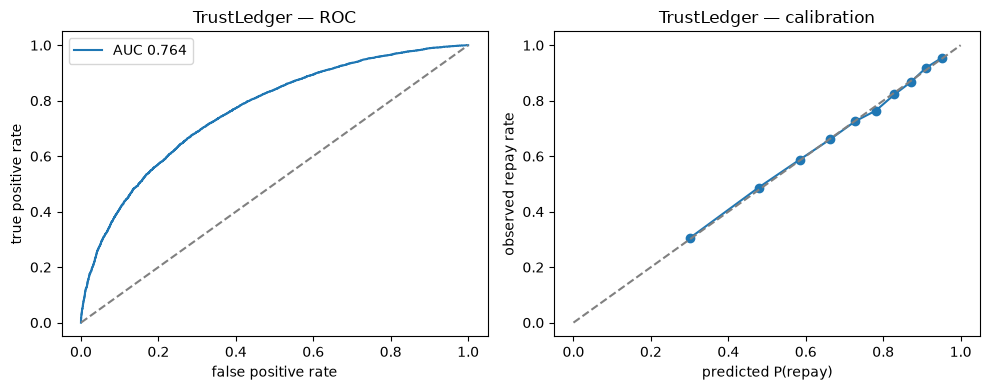

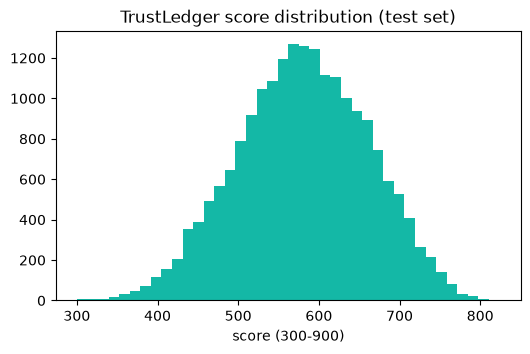

In [9]:
FEATURES = ["monthly_inflow_bdt", "income_volatility", "months_on_wallet", "txn_per_month", "bills_on_time",
            "recharge_regularity", "savings_ratio", "sends_money_home", "bhorsha_score", "loan_to_income"]

tr, rest = train_test_split(bd, test_size=0.4, stratify=bd.repaid, random_state=SEED)
va, te = train_test_split(rest, test_size=0.5, stratify=rest.repaid, random_state=SEED)

model = fit_xgb(tr[FEATURES], tr.repaid, va[FEATURES], va.repaid, depth=4)
p_va = model.predict_proba(va[FEATURES])[:, 1]
p_te = model.predict_proba(te[FEATURES])[:, 1]
THRESHOLD = youden(va.repaid, p_va)

metrics["trustledger"] = scores(te.repaid, p_te)
print(metrics["trustledger"], "| threshold", round(THRESHOLD, 3))
plot_roc_calibration(te.repaid, p_te, "TrustLedger", "trustledger_roc_calibration")

plt.figure(figsize=(6, 3.5))
plt.hist(to_score(p_te), bins=40, color="#14B8A6")
plt.title("TrustLedger score distribution (test set)")
plt.xlabel("score (300-900)")
save("trustledger_score_distribution")

### Explanations

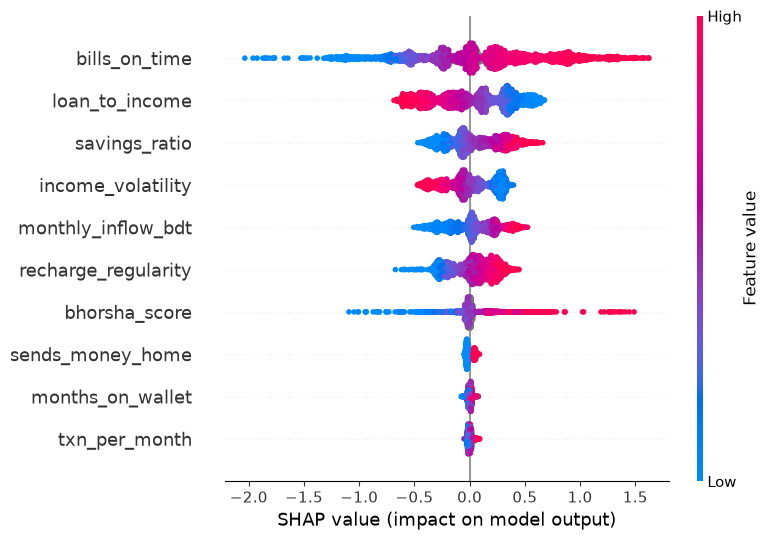

In [10]:
explainer = shap.TreeExplainer(model)
sample = te[FEATURES].sample(3000, random_state=SEED)
shap.summary_plot(explainer.shap_values(sample), sample, show=False)
save("trustledger_shap")

reasons = {  # feature: (good, bad)
    "bills_on_time": ("বিল সময়মতো পরিশোধ", "বিল পরিশোধে দেরি"),
    "income_volatility": ("আয় স্থিতিশীল", "আয় অনিয়মিত"),
    "monthly_inflow_bdt": ("মাসিক আয় ভালো", "মাসিক আয় কম"),
    "savings_ratio": ("নিয়মিত সঞ্চয়", "সঞ্চয় কম"),
    "recharge_regularity": ("নিয়মিত মোবাইল রিচার্জ", "রিচার্জ অনিয়মিত"),
    "months_on_wallet": ("দীর্ঘ ওয়ালেট ইতিহাস", "ওয়ালেট ইতিহাস কম"),
    "txn_per_month": ("নিয়মিত লেনদেন", "লেনদেন কম"),
    "sends_money_home": ("নিয়মিত পরিবারে টাকা পাঠান", "রেমিট্যান্স অনিয়মিত"),
    "bhorsha_score": ("ভরসা মূল্যায়নে ভালো ফল", "ভরসা মূল্যায়নে উন্নতি দরকার"),
    "loan_to_income": ("ঋণের পরিমাণ আয়ের সাথে মানানসই", "ঋণের পরিমাণ আয়ের তুলনায় বেশি"),
}
tips = {
    "bills_on_time": "প্রতিটি বিল নির্ধারিত তারিখের আগে পরিশোধ করুন।",
    "income_volatility": "আয়ের একটি নিয়মিত উৎস দেখাতে ওয়ালেটে আয় জমা রাখুন।",
    "savings_ratio": "প্রতি মাসে আয়ের অন্তত ৫% সঞ্চয় করুন।",
    "loan_to_income": "ছোট অঙ্কের ঋণ দিয়ে শুরু করুন, সময়মতো পরিশোধে সীমা বাড়বে।",
    "months_on_wallet": "নিয়মিত ওয়ালেট ব্যবহার চালিয়ে যান।",
    "recharge_regularity": "নিয়মিত সময়ে মোবাইল রিচার্জ করুন।",
    "bhorsha_score": "ভরসা মূল্যায়ন আবার দিন।",
}

def explain(x, k=2, min_impact=0.02):
    sv = explainer.shap_values(x)[0]
    usable = [i for i in range(len(FEATURES)) if not pd.isna(x.iloc[0, i]) and abs(sv[i]) >= min_impact]
    good = sorted([i for i in usable if sv[i] > 0], key=lambda i: -sv[i])[:k]
    bad = sorted([i for i in usable if sv[i] < 0], key=lambda i: sv[i])[:k]
    return {"good": [reasons[FEATURES[i]][0] for i in good],
            "bad": [reasons[FEATURES[i]][1] for i in bad],
            "tips": [tips[FEATURES[i]] for i in bad if FEATURES[i] in tips]}

### Fairness

The model never sees gender or region. They are only used afterwards to set per-group thresholds so every group
gets approved at the same rate. That's justified here because true repayment rates are equal across groups.

               before                       after              
        approval_rate    tpr    fpr approval_rate    tpr    fpr
g                                                              
F_rural         0.553  0.673  0.286         0.582  0.700  0.318
F_urban         0.610  0.716  0.327         0.595  0.700  0.314
M_rural         0.565  0.685  0.292         0.595  0.715  0.325
M_urban         0.653  0.745  0.383         0.587  0.681  0.313
approval gap 0.100 -> 0.013 | equalized odds gap 0.097 -> 0.034
balanced accuracy 0.694 -> 0.691


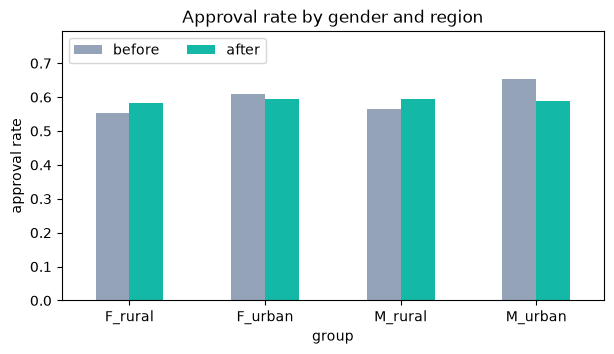

In [11]:
target_rate = (p_va >= THRESHOLD).mean()
group_thr = {g: float(np.quantile(p_va[va.group == g], 1 - target_rate)) for g in va.group.unique()}

before = (p_te >= THRESHOLD).astype(int)
after = np.array([int(p >= group_thr[g]) for p, g in zip(p_te, te.group)])
tb, dp_b, _, eo_b = group_table(te.repaid, before, te.group)
ta, dp_a, _, eo_a = group_table(te.repaid, after, te.group)
print(pd.concat({"before": tb, "after": ta}, axis=1).round(3))
print(f"approval gap {dp_b:.3f} -> {dp_a:.3f} | equalized odds gap {eo_b:.3f} -> {eo_a:.3f}")
print(f"balanced accuracy {balanced_accuracy_score(te.repaid, before):.3f} -> {balanced_accuracy_score(te.repaid, after):.3f}")

pd.DataFrame({"before": tb.approval_rate, "after": ta.approval_rate}).plot.bar(rot=0, figsize=(7, 3.5), color=["#94A3B8", "#14B8A6"])
plt.ylim(0, min(1, ta.approval_rate.max() + 0.2))
plt.legend(loc="upper left", ncol=2)
plt.title("Approval rate by gender and region")
plt.xlabel("group")
plt.ylabel("approval rate")
save("trustledger_fairness")

metrics["trustledger"].update({"approval_gap_before": round(dp_b, 3), "approval_gap_after": round(dp_a, 3),
                               "eq_odds_gap_before": round(eo_b, 3), "eq_odds_gap_after": round(eo_a, 3)})

### Inclusion lift

Traditional rule: bank account plus a salary slip, or a bank account and income of at least 25,000 BDT.
How many people does TrustLedger approve that this rule turns away, and do they repay?

{'bank_rule_approval': 0.117, 'trustledger_approval': 0.59, 'newly_included': 0.503, 'repay_rate_bank_approved': 0.806, 'repay_rate_newly_included': 0.836}


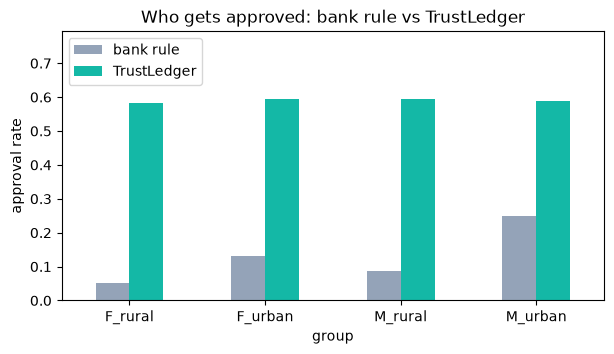

In [12]:
bank_rule = ((te.has_bank_account == 1) & ((te.has_salary_slip == 1) | (te.monthly_inflow_bdt >= 25000))).astype(int).values
new = (after == 1) & (bank_rule == 0)

lift = {"bank_rule_approval": bank_rule.mean(), "trustledger_approval": after.mean(),
        "newly_included": new.mean(),
        "repay_rate_bank_approved": te.repaid.values[bank_rule == 1].mean(),
        "repay_rate_newly_included": te.repaid.values[new].mean()}
lift = {k: round(float(v), 3) for k, v in lift.items()}
metrics["trustledger"]["inclusion"] = lift
print(lift)

by_group = pd.DataFrame({"bank rule": pd.Series(bank_rule, index=te.index).groupby(te.group).mean(),
                         "TrustLedger": pd.Series(after, index=te.index).groupby(te.group).mean()})
by_group.plot.bar(rot=0, figsize=(7, 3.5), color=["#94A3B8", "#14B8A6"])
plt.ylim(0, min(1, by_group.values.max() + 0.2))
plt.legend(loc="upper left")
plt.title("Who gets approved: bank rule vs TrustLedger")
plt.ylabel("approval rate")
save("trustledger_inclusion_lift")

### Federated learning

Each division acts as a device. A logistic model is trained locally, updates are clipped and noised, then averaged (FedAvg).
Raw rows never leave their client. In the app this loop is replaced by Flower clients.

federated AUC 0.7574 vs central 0.7644


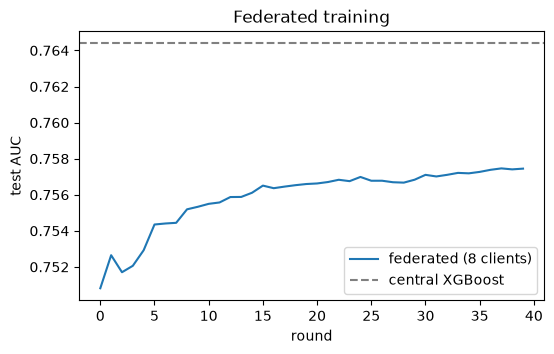

In [13]:
fill = tr[FEATURES].median()
mu, sd = tr[FEATURES].fillna(fill).mean(), tr[FEATURES].fillna(fill).std() + 1e-9
prep = lambda d: np.c_[((d[FEATURES].fillna(fill) - mu) / sd).values, d[FEATURES].isna().values.astype(float)]

clients = [(prep(g), g.repaid.values) for _, g in tr.groupby("division")]
X_te_fl = prep(te)
w = np.zeros(clients[0][0].shape[1] + 1)
sizes = np.array([len(y) for _, y in clients]) / sum(len(y) for _, y in clients)

def local_step(w, X, y, epochs=3, lr=0.1):
    for _ in range(epochs):
        err = sig(X @ w[:-1] + w[-1]) - y
        w = w - lr * np.r_[X.T @ err / len(y) + 1e-3 * w[:-1], err.mean()]
    return w

history = []
for _ in range(40):
    updates = []
    for X, y in clients:
        d = local_step(w.copy(), X, y) - w
        d *= min(1, 1 / (np.linalg.norm(d) + 1e-12))
        updates.append(d + rng.normal(0, 0.01, d.shape))
    w = w + sum(s * u for s, u in zip(sizes, updates))
    history.append(roc_auc_score(te.repaid, sig(X_te_fl @ w[:-1] + w[-1])))

metrics["trustledger"]["federated_auc"] = round(history[-1], 4)
print(f"federated AUC {history[-1]:.4f} vs central {metrics['trustledger']['auc']:.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(history, label="federated (8 clients)")
plt.axhline(metrics["trustledger"]["auc"], ls="--", c="grey", label="central XGBoost")
plt.xlabel("round"); plt.ylabel("test AUC"); plt.legend()
plt.title("Federated training")
save("trustledger_federated")

### Example: Moon, 24, garment worker, no bank account

In [14]:
moon = {"monthly_inflow_bdt": 14000, "income_volatility": 0.10, "months_on_wallet": 30, "txn_per_month": 18,
          "bills_on_time": 0.97, "recharge_regularity": 0.90, "savings_ratio": 0.04, "sends_money_home": 1,
          "bhorsha_score": np.nan, "loan_to_income": 4.0}
x = pd.DataFrame([moon])[FEATURES].astype(float)
p = float(model.predict_proba(x)[0, 1])
result = {"p_repay": round(p, 3), "score": int(to_score(np.array([p]))[0]),
          "approved": bool(p >= group_thr["F_urban"]), **explain(x)}
print(json.dumps(result, ensure_ascii=False, indent=2))

{
  "p_repay": 0.934,
  "score": 691,
  "approved": true,
  "good": [
    "বিল সময়মতো পরিশোধ",
    "নিয়মিত মোবাইল রিচার্জ"
  ],
  "bad": [
    "সঞ্চয় কম"
  ],
  "tips": [
    "প্রতি মাসে আয়ের অন্তত ৫% সঞ্চয় করুন।"
  ]
}


## 5. Save

In [15]:
model.save_model(f"{MODELS}/trustledger_xgb.json")
np.save(f"{MODELS}/federated_weights.npy", w)
json.dump({"features": FEATURES, "threshold": THRESHOLD, "group_thresholds": group_thr,
           "score_scale": {"points_at_4_to_1": 600, "points_to_double_odds": 50, "range": [300, 900]},
           "reasons": reasons, "tips": tips},
          open(f"{MODELS}/trustledger_meta.json", "w"), ensure_ascii=False, indent=2)
json.dump(metrics, open(f"{FIGS}/metrics.json", "w"), indent=2)

print("models:", sorted(os.listdir(MODELS)))
print("figures:", sorted(os.listdir(FIGS)))

models: ['federated_weights.npy', 'homecredit_alt_xgb.json', 'homecredit_meta.json', 'lendingclub_xgb.json', 'trustledger_meta.json', 'trustledger_xgb.json']
figures: ['findex_bangladesh.png', 'homecredit_feature_sets.png', 'homecredit_roc_calibration.png', 'homecredit_shap.png', 'lendingclub_roc_calibration.png', 'metrics.json', 'trustledger_fairness.png', 'trustledger_federated.png', 'trustledger_inclusion_lift.png', 'trustledger_roc_calibration.png', 'trustledger_score_distribution.png', 'trustledger_shap.png']
